# Experiment: Cross-Session Affine Alignment via Eye Fiducials

**Question:** does a similarity transform (translation + rotation + uniform scale) fit to the two medial-edge-eye landmarks produce better cross-session spatial comparability than midpoint centering alone?

**Why eyes (not nose):** the resting nose position may shift post-stroke; eyes are stable post-stroke and are a reliable landmark for camera-drift correction.

**Procedure:**

1. Load raw (uncentered) DLC outputs for several baseline sessions of one animal.
2. For each session, compute the median L_eye and R_eye positions (likelihood-gated).
3. Visualize per-session eye positions BEFORE alignment.
4. Define a canonical reference frame as the mean of per-session medians across baseline.
5. Compute a per-session similarity transform that maps (L_eye, R_eye) → canonical.
6. Apply the transforms, visualize eye positions AFTER alignment.
7. Compare tongue heatmaps for one session under two alignment regimes:
   - spout-midpoint-centered (current default for tongue)
   - eye-affine-aligned (proposed)

**Interpretation criteria:**

- If per-session eye positions collapse tightly onto the canonical reference after alignment → transform is fitting correctly.
- If cross-session variance of non-fiducial landmarks (e.g., tongue rest position, spout positions) is visibly tighter after alignment → affine transform is correcting real camera drift.
- If both look similar, midpoint centering is sufficient and Phase 4.5 isn't worth building.

This notebook is **exploratory**: no tests, no persistent outputs, no parity requirement. Throwaway-friendly — re-run freely with different animals/dates to check whether the hypothesis generalizes.

In [1]:
# ============================================================
# USER INPUTS — edit, then run all cells.
# ============================================================

ANIMAL = "PS46"

# Baseline session dates to compute canonical reference from.
# Use dates BEFORE the animal's stroke_date (from configs/animals.yaml).
# Pick 4-6 baseline sessions for a reasonable canonical estimate.
import datetime
BASELINE_DATES = [
    datetime.date(2025, 3, 7),
    datetime.date(2025, 3, 8),
    datetime.date(2025, 3, 9),
    datetime.date(2025, 3, 10),
    datetime.date(2025, 3, 11),
    datetime.date(2025, 3, 12),
    datetime.date(2025, 3, 13),  # last pre-stroke session (day 0 per convention)
]

# One session to use for the comparison heatmap.
# Can be baseline or post-stroke — both work for the camera-drift question.
COMPARE_DATE = datetime.date(2025, 3, 10)

# Likelihood gate for eye fiducial medians.
EYE_LIKELIHOOD_THRESHOLD = 0.9  # Eyes usually detected cleanly; use a strict threshold.

# Bodypart to use for the heatmap comparison (spatial distribution under each alignment).
COMPARE_BODYPART = "tongue"
TONGUE_LIKELIHOOD_THRESHOLD = 0.7

# Where to save plot PNGs and a summary text file so Cowork can read them.
# Under `jupyter nbconvert --execute --inplace` the kernel cwd is the
# notebook's directory; under Jupyter Lab / classic the user may have
# started the kernel from the repo root. Handle both so the outputs
# always land in notebooks/experiments/outputs/.
from pathlib import Path
_cwd = Path.cwd().resolve()
if _cwd.name == "experiments" and _cwd.parent.name == "notebooks":
    OUTPUT_DIR = _cwd / "outputs"
else:
    OUTPUT_DIR = _cwd / "notebooks" / "experiments" / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Saving outputs to: {OUTPUT_DIR}")

Saving outputs to: /Users/Priya2/Github/stroke_orofacial_pipeline/notebooks/experiments/outputs


In [2]:
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from stroke_orofacial.paths import PathResolver
from stroke_orofacial.dlc_io.loaders import discover_dlc_filtered_files, read_dlc

resolver = PathResolver()

# Eye bodypart keys — confirmed via user report that the DLC output uses
# short names (L_eye / R_eye), not the long "medial_edge_*" names that
# configs/defaults.yaml currently lists (stale; to be fixed separately).
L_EYE = "L_eye"
R_EYE = "R_eye"

In [3]:
# Helper: load raw DLC for one session and extract median eye positions.

def _bodyparts_in(df):
    """Return sorted unique bodypart names (strip trailing _x/_y/_likelihood)."""
    suffixes = ("_x", "_y", "_likelihood")
    names = set()
    for c in df.columns:
        for sfx in suffixes:
            if c.endswith(sfx):
                names.add(c[: -len(sfx)])
                break
    return sorted(names)

def _assert_eye_cols_present(df, where=""):
    missing = [bp for bp in (L_EYE, R_EYE) if f"{bp}_x" not in df.columns]
    if missing:
        bps = _bodyparts_in(df)
        eye_like = [bp for bp in bps if "eye" in bp.lower()]
        raise KeyError(
            f"Eye bodyparts {missing} not found in DLC DataFrame {where}.\n"
            f"  Bodyparts present: {bps}\n"
            f"  Bodyparts containing 'eye': {eye_like}\n"
            f"  Update L_EYE / R_EYE in cell 2 to the correct names."
        )

def load_dlc_for_session(animal, date):
    """Load raw DLC H5 → DataFrame with bodypart_x/y/likelihood columns."""
    dlc_dir = resolver.dlc_output_dir(animal)
    date_str = date.strftime("%Y%m%d")
    h5_files = discover_dlc_filtered_files(dlc_dir, date_str)
    if not h5_files:
        raise FileNotFoundError(f"No DLC H5 for {animal} {date_str}")
    return read_dlc(h5_files[0])

def median_eye_position(df, bodypart, likelihood_threshold):
    """Median (x, y) for one eye, filtered by likelihood."""
    x = df[f"{bodypart}_x"].values.astype(np.float64)
    y = df[f"{bodypart}_y"].values.astype(np.float64)
    lik = df[f"{bodypart}_likelihood"].values.astype(np.float64)
    m = (lik >= likelihood_threshold) & np.isfinite(x) & np.isfinite(y)
    if not np.any(m):
        return None, None
    return float(np.median(x[m])), float(np.median(y[m]))

# Load per-session eye medians for all baseline dates.
per_session = {}
for i, d in enumerate(BASELINE_DATES):
    try:
        df = load_dlc_for_session(ANIMAL, d)
    except FileNotFoundError as e:
        print(f"  skip {d}: {e}")
        continue
    # One-time diagnostic: confirm the expected eye bodypart names exist.
    if i == 0:
        print(f"Bodyparts in DLC output for {ANIMAL} {d}: {_bodyparts_in(df)}")
    _assert_eye_cols_present(df, where=f"for {ANIMAL} {d}")
    l_x, l_y = median_eye_position(df, L_EYE, EYE_LIKELIHOOD_THRESHOLD)
    r_x, r_y = median_eye_position(df, R_EYE, EYE_LIKELIHOOD_THRESHOLD)
    if None in (l_x, l_y, r_x, r_y):
        print(f"  skip {d}: eyes not detected at threshold {EYE_LIKELIHOOD_THRESHOLD}")
        continue
    per_session[d] = {"df": df, "L": (l_x, l_y), "R": (r_x, r_y)}
    print(f"  {d}: L=({l_x:.1f}, {l_y:.1f})  R=({r_x:.1f}, {r_y:.1f})")

print(f"\nLoaded {len(per_session)} baseline sessions.")

Bodyparts in DLC output for PS46 2025-03-07: ['L_eye', 'L_spout', 'L_whiskers_1', 'L_whiskers_2', 'L_whiskers_3', 'R_eye', 'R_spout', 'R_whiskers_1', 'R_whiskers_2', 'R_whiskers_3', 'jaw', 'nose', 'tongue']
  2025-03-07: L=(527.8, 89.2)  R=(270.4, 89.2)


  2025-03-08: L=(518.3, 60.6)  R=(260.9, 61.4)


  2025-03-09: L=(519.7, 61.4)  R=(261.4, 62.5)


  2025-03-10: L=(517.0, 70.3)  R=(259.0, 72.3)


  2025-03-11: L=(520.8, 71.0)  R=(263.4, 73.1)


  2025-03-12: L=(523.0, 68.4)  R=(265.8, 69.9)


  2025-03-13: L=(515.6, 69.0)  R=(260.1, 70.0)

Loaded 7 baseline sessions.


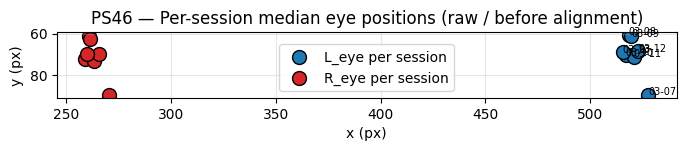


Cross-session eye-position spread (std in px):
  L_eye: x_std=3.80  y_std=8.73
  R_eye: x_std=3.68  y_std=8.49
  Eye-to-eye distance: mean=257.30  std=0.84


In [4]:
# Visualize per-session eye positions BEFORE alignment.
# Tight clustering = stable camera. Scatter = camera drift.

fig, ax = plt.subplots(1, 1, figsize=(7, 7))
l_xs = [s["L"][0] for s in per_session.values()]
l_ys = [s["L"][1] for s in per_session.values()]
r_xs = [s["R"][0] for s in per_session.values()]
r_ys = [s["R"][1] for s in per_session.values()]

ax.scatter(l_xs, l_ys, c="tab:blue", s=100, label=f"{L_EYE} per session", edgecolor="black")
ax.scatter(r_xs, r_ys, c="tab:red", s=100, label=f"{R_EYE} per session", edgecolor="black")
for d, s in per_session.items():
    ax.annotate(d.strftime("%m-%d"), s["L"], fontsize=7)

ax.set_aspect("equal")
ax.invert_yaxis()  # image coordinates: y increases downward
ax.set_title(f"{ANIMAL} — Per-session median eye positions (raw / before alignment)")
ax.set_xlabel("x (px)")
ax.set_ylabel("y (px)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_before_alignment.png", dpi=150, bbox_inches="tight")
plt.show()

# Quantification
l_std_x, l_std_y = float(np.std(l_xs)), float(np.std(l_ys))
r_std_x, r_std_y = float(np.std(r_xs)), float(np.std(r_ys))
eye_distances = [np.hypot(r[0] - l[0], r[1] - l[1]) for l, r in ((s["L"], s["R"]) for s in per_session.values())]
ee_mean, ee_std = float(np.mean(eye_distances)), float(np.std(eye_distances))

print(f"\nCross-session eye-position spread (std in px):")
print(f"  {L_EYE}: x_std={l_std_x:.2f}  y_std={l_std_y:.2f}")
print(f"  {R_EYE}: x_std={r_std_x:.2f}  y_std={r_std_y:.2f}")
print(f"  Eye-to-eye distance: mean={ee_mean:.2f}  std={ee_std:.2f}")

# Record for summary
summary_lines = [
    f"=== Eye-Affine Alignment Experiment — {ANIMAL} ===",
    f"",
    f"Baseline sessions loaded: {len(per_session)} of {len(BASELINE_DATES)} requested",
    f"Eye likelihood threshold: {EYE_LIKELIHOOD_THRESHOLD}",
    f"",
    f"== Before alignment (cross-session eye-position spread) ==",
    f"  L_eye: x_std={l_std_x:.3f} px, y_std={l_std_y:.3f} px",
    f"  R_eye: x_std={r_std_x:.3f} px, y_std={r_std_y:.3f} px",
    f"  Eye-to-eye distance: mean={ee_mean:.3f} px, std={ee_std:.3f} px",
    f""
]


In [5]:
# Canonical reference frame: mean of per-session medians across baseline.

L_canonical = (np.mean(l_xs), np.mean(l_ys))
R_canonical = (np.mean(r_xs), np.mean(r_ys))
print(f"Canonical reference (average across {len(per_session)} baseline sessions):")
print(f"  {L_EYE}: ({L_canonical[0]:.2f}, {L_canonical[1]:.2f})")
print(f"  {R_EYE}: ({R_canonical[0]:.2f}, {R_canonical[1]:.2f})")

Canonical reference (average across 7 baseline sessions):
  L_eye: (520.31, 69.99)
  R_eye: (263.01, 71.20)


In [6]:
# Similarity transform utilities (translation + rotation + uniform scale).
# Two-fiducial exact fit using complex-number arithmetic.

def fit_similarity_2pt(src_pts, dst_pts):
    """Compute 4-param similarity transform mapping src_pts -> dst_pts.

    src_pts, dst_pts: arrays of shape (2, 2) — two 2D points each.
    Returns: dict with scale, theta_rad, tx, ty, matrix (2x3), and a callable apply(points).
    """
    s = src_pts[:, 0] + 1j * src_pts[:, 1]
    d = dst_pts[:, 0] + 1j * dst_pts[:, 1]
    a = (d[0] - d[1]) / (s[0] - s[1])
    b = d[0] - a * s[0]
    scale = float(np.abs(a))
    theta_rad = float(np.angle(a))
    tx, ty = float(b.real), float(b.imag)
    c, sn = np.cos(theta_rad), np.sin(theta_rad)
    M = np.array([[scale * c, -scale * sn, tx],
                  [scale * sn,  scale * c,  ty]])
    def apply(points):
        pts = np.asarray(points, dtype=np.float64)
        pts_h = np.column_stack([pts, np.ones(len(pts))])
        return (M @ pts_h.T).T
    return {"scale": scale, "theta_rad": theta_rad, "tx": tx, "ty": ty, "M": M, "apply": apply}

# Compute per-session transforms: each maps session eye positions -> canonical.
canonical_pts = np.array([L_canonical, R_canonical])

summary_lines.append("== Per-session similarity transforms (session -> canonical) ==")
summary_lines.append(f"  {'Date':<12} {'scale':<12} {'rot (deg)':<12} {'tx (px)':<12} {'ty (px)':<12}")
for d, s in per_session.items():
    src = np.array([s["L"], s["R"]])
    transform = fit_similarity_2pt(src, canonical_pts)
    s["transform"] = transform
    rot_deg = float(np.degrees(transform["theta_rad"]))
    line = f"  {d}   scale={transform['scale']:.4f}  rot_deg={rot_deg:+.4f}  t=({transform['tx']:+.2f}, {transform['ty']:+.2f})"
    print(line)
    summary_lines.append(f"  {str(d):<12} {transform['scale']:<12.4f} {rot_deg:<+12.4f} {transform['tx']:<+12.2f} {transform['ty']:<+12.2f}")

# Summary stats of the transforms
scales = [s["transform"]["scale"] for s in per_session.values()]
rots_deg = [np.degrees(s["transform"]["theta_rad"]) for s in per_session.values()]
summary_lines.append("")
summary_lines.append(f"== Transform summary ==")
summary_lines.append(f"  Scale:    mean={np.mean(scales):.5f}  std={np.std(scales):.5f}  range=[{min(scales):.5f}, {max(scales):.5f}]")
summary_lines.append(f"  Rotation: mean={np.mean(rots_deg):+.4f} deg  std={np.std(rots_deg):.4f} deg  range=[{min(rots_deg):+.4f}, {max(rots_deg):+.4f}]")
summary_lines.append("")
summary_lines.append("Interpretation:")
summary_lines.append("  - Rotation std > 0.5 deg => real tilt drift; affine alignment valuable.")
summary_lines.append("  - Scale std > 0.01 (1%) => real zoom drift; affine alignment valuable.")
summary_lines.append("  - Both tiny => camera stable; Phase 4.5 may not be worth building.")


  2025-03-07   scale=0.9999  rot_deg=-0.2561  t=(-7.79, -16.79)
  2025-03-08   scale=0.9995  rot_deg=-0.1055  t=(+2.11, +10.32)
  2025-03-09   scale=0.9961  rot_deg=-0.0222  t=(+2.62, +9.03)
  2025-03-10   scale=0.9971  rot_deg=+0.1705  t=(+4.99, -1.67)
  2025-03-11   scale=0.9999  rot_deg=+0.2035  t=(-0.14, -2.85)
  2025-03-12   scale=1.0003  rot_deg=+0.0642  t=(-2.83, +0.98)
  2025-03-13   scale=1.0071  rot_deg=-0.0550  t=(+0.99, +1.00)


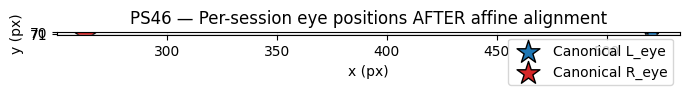


Expect all scatter points to overlap the stars. Any residual offset is numerical precision.


In [7]:
# Apply transforms and visualize eyes AFTER alignment.
# If transforms are correct, all per-session eye points should land ON the canonical reference.

fig, ax = plt.subplots(1, 1, figsize=(7, 7))
for d, s in per_session.items():
    aligned = s["transform"]["apply"](np.array([s["L"], s["R"]]))
    ax.scatter(aligned[:, 0], aligned[:, 1], c=["tab:blue", "tab:red"], s=80, alpha=0.7, edgecolor="black")

ax.scatter(*L_canonical, c="tab:blue", s=300, marker="*", edgecolor="black", label=f"Canonical {L_EYE}")
ax.scatter(*R_canonical, c="tab:red", s=300, marker="*", edgecolor="black", label=f"Canonical {R_EYE}")

ax.set_aspect("equal")
ax.invert_yaxis()
ax.set_title(f"{ANIMAL} — Per-session eye positions AFTER affine alignment")
ax.set_xlabel("x (px)")
ax.set_ylabel("y (px)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_after_alignment.png", dpi=150, bbox_inches="tight")
plt.show()
print("\nExpect all scatter points to overlap the stars. Any residual offset is numerical precision.")


Tongue frames with likelihood >= 0.7: 76836

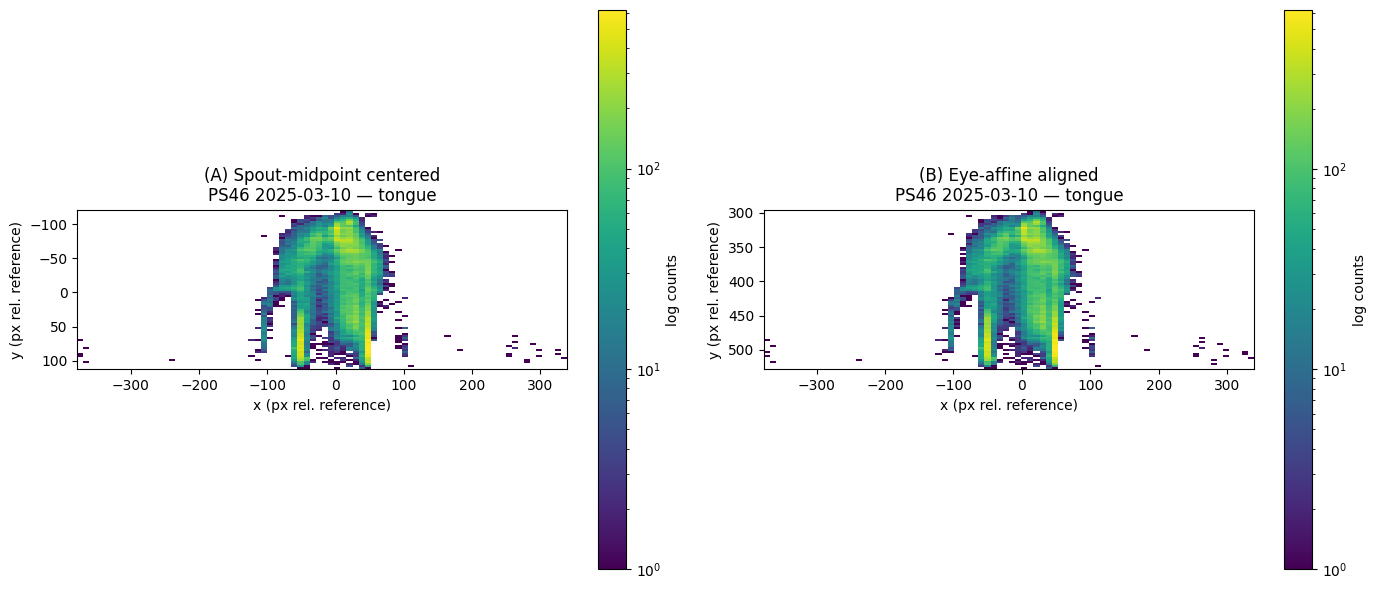



Summary written to: /Users/Priya2/Github/stroke_orofacial_pipeline/notebooks/experiments/outputs/summary.txt
Plots saved to: /Users/Priya2/Github/stroke_orofacial_pipeline/notebooks/experiments/outputs
  - 01_before_alignment.png
  - 02_after_alignment.png
  - 03_heatmap_comparison.png


In [8]:
# Compare one session's tongue distribution under two alignment regimes:
#   (A) Spout-midpoint-centered (current default for tongue)
#   (B) Eye-affine-aligned (proposed)

if COMPARE_DATE not in per_session:
    raise ValueError(f"{COMPARE_DATE} not in loaded sessions. Add it to BASELINE_DATES and rerun.")

s = per_session[COMPARE_DATE]
df = s["df"]

# Likelihood-gate tongue
tx_raw = df[f"{COMPARE_BODYPART}_x"].values.astype(np.float64)
ty_raw = df[f"{COMPARE_BODYPART}_y"].values.astype(np.float64)
tlik = df[f"{COMPARE_BODYPART}_likelihood"].values.astype(np.float64)
mask = (tlik >= TONGUE_LIKELIHOOD_THRESHOLD) & np.isfinite(tx_raw) & np.isfinite(ty_raw)
tongue_raw = np.column_stack([tx_raw[mask], ty_raw[mask]])
print(f"Tongue frames with likelihood >= {TONGUE_LIKELIHOOD_THRESHOLD}: {len(tongue_raw)}")

# (A) Spout-midpoint centering
lx_spout = df["L_spout_x"].values[mask]
ly_spout = df["L_spout_y"].values[mask]
rx_spout = df["R_spout_x"].values[mask]
ry_spout = df["R_spout_y"].values[mask]
llik = df["L_spout_likelihood"].values[mask]
rlik = df["R_spout_likelihood"].values[mask]
spout_mask = (llik >= 0.7) & (rlik >= 0.7)
if spout_mask.sum() == 0:
    raise RuntimeError("No spout detections passed likelihood gate — can't compute spout-midpoint center.")
spout_midpoint_x = float(np.median((lx_spout[spout_mask] + rx_spout[spout_mask]) / 2))
spout_midpoint_y = float(np.median((ly_spout[spout_mask] + ry_spout[spout_mask]) / 2))
tongue_spout_centered = tongue_raw - np.array([spout_midpoint_x, spout_midpoint_y])

# (B) Eye-affine alignment
tongue_eye_aligned = s["transform"]["apply"](tongue_raw)
canonical_eye_midpoint = np.array([
    (L_canonical[0] + R_canonical[0]) / 2,
    (L_canonical[1] + R_canonical[1]) / 2,
])
tongue_eye_aligned = tongue_eye_aligned - canonical_eye_midpoint

# Plot side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
bins = 80

for ax, (pts, title) in zip(axes, [
    (tongue_spout_centered, "(A) Spout-midpoint centered"),
    (tongue_eye_aligned, "(B) Eye-affine aligned"),
]):
    H, xed, yed = np.histogram2d(pts[:, 0], pts[:, 1], bins=bins)
    im = ax.imshow(
        H.T, origin="upper",
        extent=[xed[0], xed[-1], yed[-1], yed[0]],
        cmap="viridis", norm="log" if H.max() > 1 else None,
    )
    ax.set_title(f"{title}\n{ANIMAL} {COMPARE_DATE} — {COMPARE_BODYPART}")
    ax.set_xlabel("x (px rel. reference)")
    ax.set_ylabel("y (px rel. reference)")
    plt.colorbar(im, ax=ax, label="log counts")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_heatmap_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

# Record which session, write full summary to disk
summary_lines.append("")
summary_lines.append(f"== Heatmap comparison session ==")
summary_lines.append(f"  Compare session: {COMPARE_DATE}")
summary_lines.append(f"  Bodypart: {COMPARE_BODYPART} (likelihood >= {TONGUE_LIKELIHOOD_THRESHOLD})")
summary_lines.append(f"  Tongue frames (likelihood-gated): {len(tongue_raw)}")

summary_path = OUTPUT_DIR / "summary.txt"
summary_path.write_text("\n".join(summary_lines))
print(f"\n\nSummary written to: {summary_path}")
print(f"Plots saved to: {OUTPUT_DIR}")
print(f"  - 01_before_alignment.png")
print(f"  - 02_after_alignment.png")
print(f"  - 03_heatmap_comparison.png")


## Interpretation checklist

After running the above cells, evaluate:

1. **Before-alignment eye scatter (cell 4)** — is the cross-session spread large (>5 px)? If tiny, camera is already stable and affine alignment won't help much.
2. **After-alignment eye scatter (cell 7)** — do all points collapse to the stars? If yes, transform is mathematically correct. (Residual is numerical precision only.)
3. **Rotation magnitudes (cell 6)** — are any session rotations non-trivial (> 0.5°)? Large rotations across baseline sessions would indicate the camera was tilted differently across days; eye-affine alignment is correcting this.
4. **Scale factors (cell 6)** — do any session scales deviate from 1.0 by more than 1-2%? Non-unity scale means eye-to-eye distance differed across sessions, which would indicate camera zoom drift or true anatomy change (the latter shouldn't happen in adults).
5. **Tongue heatmap comparison (cell 8)** — which mode produces a cleaner, tighter distribution? If eye-affine looks similar to spout-midpoint, they're equivalent for this session; building Phase 4.5 would be low-value. If eye-affine looks visibly tighter or more anatomically plausible, Phase 4.5 is worth building.

**To extend**: rerun with a post-stroke `COMPARE_DATE` to check that the eye transform still works (the eyes are stable post-stroke). If the post-stroke heatmap looks stable under eye-affine but drifts under spout-midpoint, that's additional evidence for Phase 4.5.

**To decide**: does this experiment motivate building a real `Phase 4.5 — Optional Affine Cross-Session Alignment` mini-phase, or can we stay with midpoint centering?

Share findings in Cowork; we'll decide the path forward from there.